# Population change point: example traces vs noise variance, f = 260 pA

Mirror of `CPA_population_traces.ipynb` with the autapse strength fixed at f = 260 pA and the noise variance
varied instead (all variances in the saved mean-step run), for small steps (dH ≤ 8 pA):

1. single neuron responses: membrane voltage (re-simulated) and spike rasters (saved trials)
2. population PSTHs of k trials, as scored by the PSTH change point analysis

In [39]:
import inspect
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()
warnings.filterwarnings('ignore')

from CPA_with_AQUA import *

In [40]:
tag = 'N250'
SAVE = False
F = 270                             # pA, autapse strength
H_EX = [0, 2, 4, 6, 8]              # pA, step heights
T_DISCARD = 200     # ms, initial transient
PSTH_BIN = 25       # ms
K = 10              # trials per PSTH
N_RES = 20          # resamples per condition

sim = {k: p.default for k, p in inspect.signature(simulate_runs).parameters.items()
       if p.default is not inspect.Parameter.empty}

with open(f'CPA_cusum_mean_{tag}_spikes.pickle', 'rb') as file:
    saved = pickle.load(file)

print(f"SAVED: {saved.keys}")

T, true_cp, N_REP = saved['T'], saved['changepoint'], saved['N_repeats']
WARM = {k: saved.get(k, d) for k, d in [('random_init', False), ('t_warmup', 0), ('var_warmup', 0)]}
V_EX = [float(v) for v in saved['var']]    # pA², noise variances
V_COLORS = dict(zip(V_EX, sns.color_palette('viridis', len(V_EX))))
CONDITIONS = [(v, h, f) for v in saved['var'] for h in saved['d_H'] for f in saved['f_values']]
print(f"repeats: {N_REP}, T = {T} ms, change point at {true_cp} ms, e = {sim['e']}, τ = {sim['tau']} ms, var = {V_EX}, {WARM}")


def spikes(rep, v, h):
    s = np.asarray(saved['spikes'][(rep, v, h, F)], dtype = float)
    return s[~np.isnan(s)]


def condition_psths(v, h, f, seed = 0):
    '''the N_RES k-trial PSTHs (raw counts) psth_cusum_analysis scored for this condition (same seed)'''
    i = CONDITIONS.index((v, h, f))
    trials = [saved['spikes'][(rep, v, h, f)] for rep in range(N_REP)]
    return psth_resamples(trials, K, N_RES, PSTH_BIN, T, T_DISCARD, np.random.default_rng([seed, i]))

SAVED: <built-in method keys of dict object at 0x746098b04680>
repeats: 250, T = 10500 ms, change point at 5500 ms, e = 0.2, τ = 2.0 ms, var = [12.5, 25.0, 37.5, 50.0], {'random_init': True, 't_warmup': 500, 'var_warmup': 250}


## 1a. Membrane voltage (re-simulated)

The saved pickle only holds spike times, so one repeat is re-simulated with `simulate_runs(save_all = True)`
for just these conditions, with the same initial-state / warm-up protocol as the saved run.
**These are new noise draws, not the saved trials.** Each (variance, step height) panel gets its own noise draw.

In [41]:
SEED = 0
np.random.seed(SEED)     # fixed so the injected current can be rebuilt in section 3
reps, (X, t, Sp) = next(simulate_runs(RS, np.array([F]), np.array(H_EX), np.array(V_EX), N_repeats = 1,
                                      T = T, changepoint = true_cp, save_all = True, **WARM))
Vm = X[:, 0, :]     # membrane voltage only
del X
idx = lambda v, h: find_idx(F, v, h, np.array([F]), np.array(V_EX), np.array(H_EX))
print(Vm.shape)

Repeats 0-0 of 1


100%|██████████| 104999/104999 [00:12<00:00, 8256.31it/s]

(20, 105000)


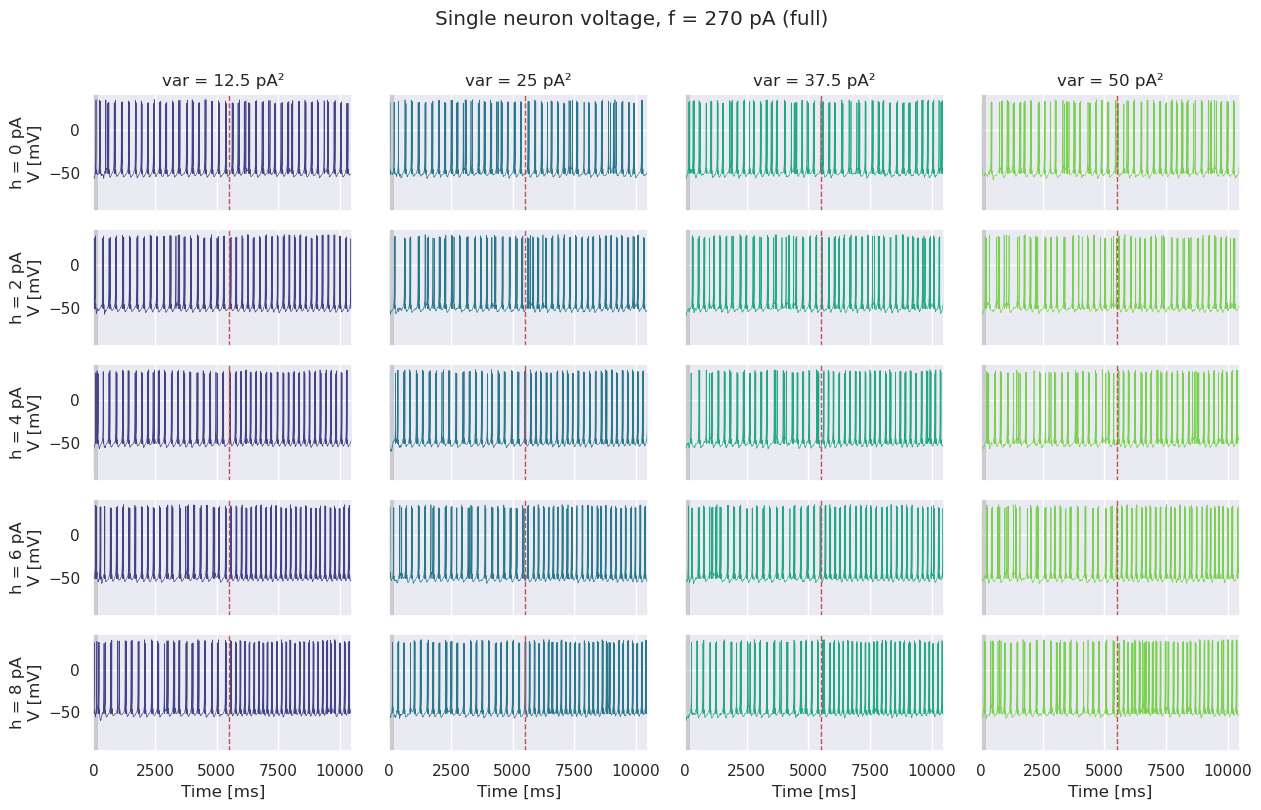

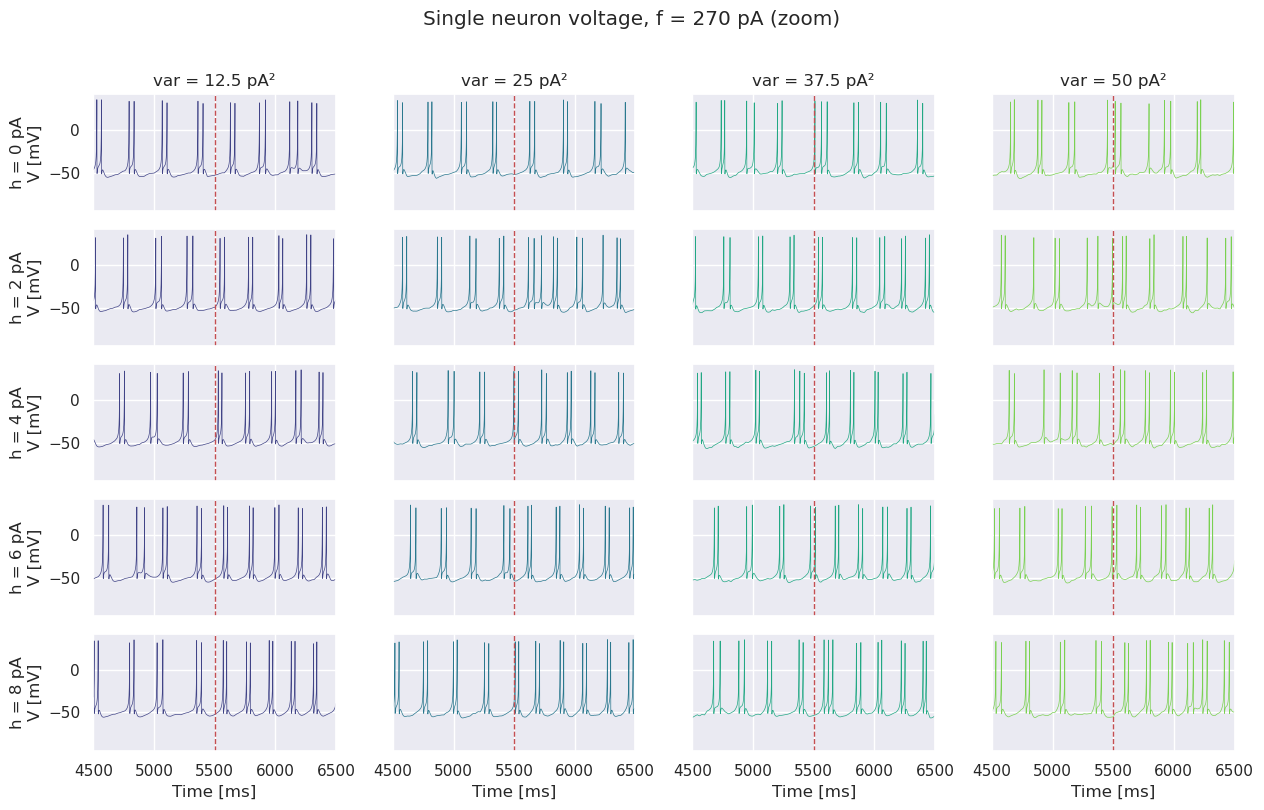

In [42]:
for xlim, name in [((0, T), 'full'), ((true_cp - 1000, true_cp + 1000), 'zoom')]:
    fig, ax = plt.subplots(len(H_EX), len(V_EX), figsize = (3.2*len(V_EX), 1.6*len(H_EX)), sharex = True, sharey = True)
    for r, h in enumerate(H_EX):
        for c, v in enumerate(V_EX):
            a = ax[r, c]
            a.plot(t, Vm[idx(v, h)], color = V_COLORS[v], lw = 0.5)
            a.axvline(true_cp, color = 'r', ls = '--', lw = 1)
            a.axvspan(0, T_DISCARD, color = 'grey', alpha = 0.3, lw = 0)
            a.set_xlim(*xlim)
            if r == 0: a.set_title(f'var = {v:g} pA²')
            if c == 0: a.set_ylabel(f'h = {h} pA\nV [mV]')
    for a in ax[-1]: a.set_xlabel('Time [ms]')
    fig.suptitle(f'Single neuron voltage, f = {F} pA ({name})', y = 1.01)
    fig.tight_layout()
    if SAVE: plt.savefig(f'./plots/{tag}_traces_f{F}_voltage_{name}.png', bbox_inches = 'tight')
    plt.show()

## 1b. Spike rasters (saved trials)

First 20 saved repeats per condition: the same trials the population analysis uses.

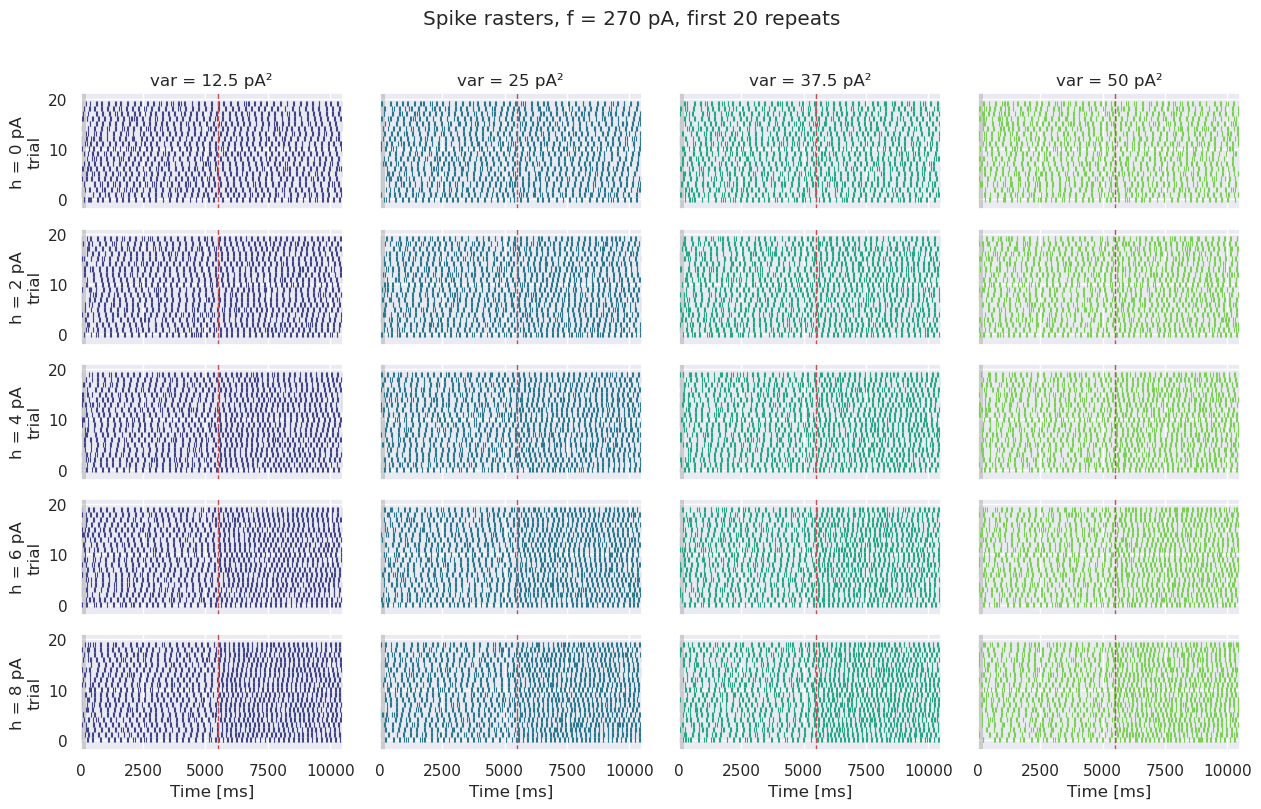

In [43]:
N_SHOW = 20
fig, ax = plt.subplots(len(H_EX), len(V_EX), figsize = (3.2*len(V_EX), 1.6*len(H_EX)), sharex = True, sharey = True)
for r, h in enumerate(H_EX):
    for c, v in enumerate(V_EX):
        a = ax[r, c]
        a.eventplot([spikes(rep, v, h) for rep in range(N_SHOW)], color = V_COLORS[v], lw = 0.8)
        a.axvline(true_cp, color = 'r', ls = '--', lw = 1)
        a.axvspan(0, T_DISCARD, color = 'grey', alpha = 0.3, lw = 0)
        a.set_xlim(0, T)
        if r == 0: a.set_title(f'var = {v:g} pA²')
        if c == 0: a.set_ylabel(f'h = {h} pA\ntrial')
for a in ax[-1]: a.set_xlabel('Time [ms]')
fig.suptitle(f'Spike rasters, f = {F} pA, first {N_SHOW} repeats', y = 1.01)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_traces_f{F}_rasters.png', bbox_inches = 'tight')
plt.show()

## 1b'. ISI distributions, pre vs post (saved trials)

ISIs pooled over all saved repeats, before and after the CP (ISIs straddling the CP and the initial transient are dropped).
Log time axis, so burst doublets (~10 ms) and regular ISIs (~200 ms) are both visible.

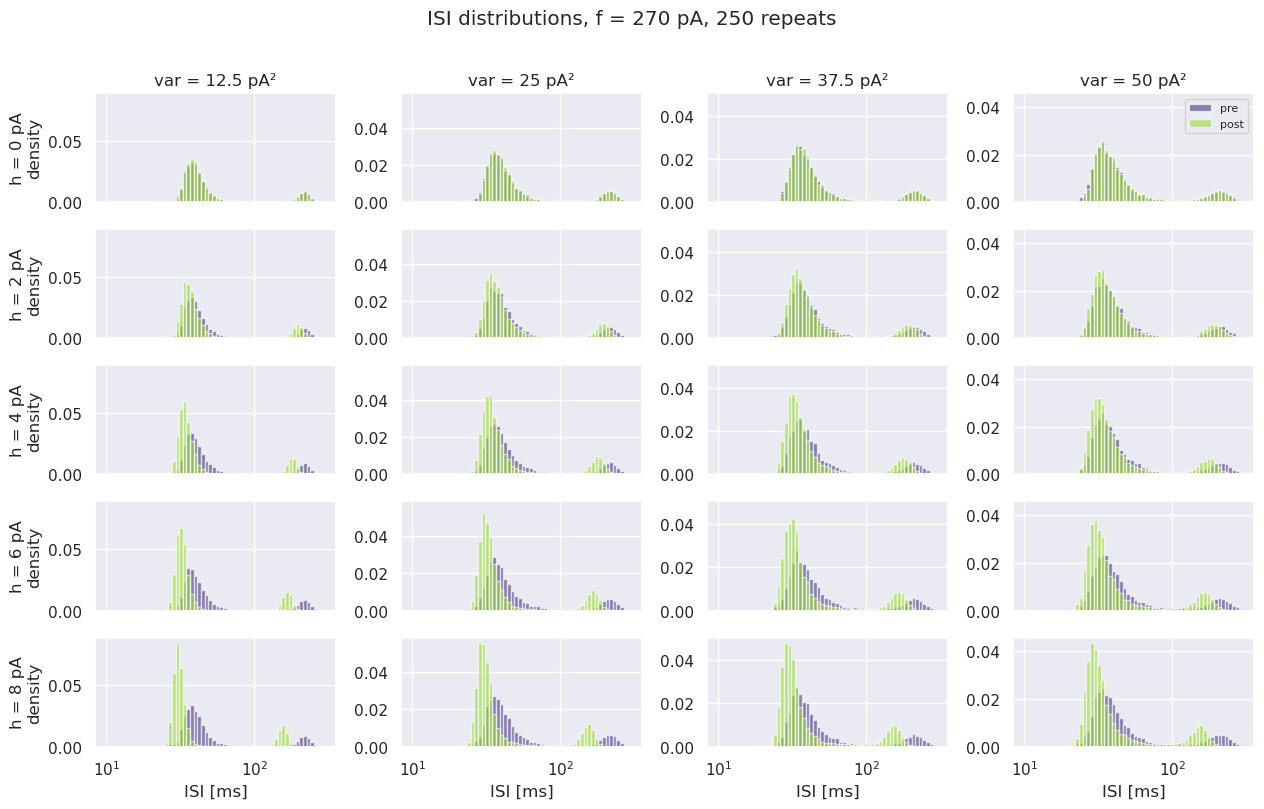

In [44]:
ISI_BINS = np.geomspace(10, 300, 61)    # ms
fig, ax = plt.subplots(len(H_EX), len(V_EX), figsize = (3.2*len(V_EX), 1.6*len(H_EX)), sharex = 'col', sharey = 'col')
for r, h in enumerate(H_EX):
    for c, v in enumerate(V_EX):
        a = ax[r, c]
        trials = [spikes(rep, v, h) for rep in range(N_REP)]
        pre, post = reference_isis([(np.diff(s[s >= T_DISCARD]), s[s >= T_DISCARD][1:]) for s in trials], true_cp)
        a.hist(pre, bins = ISI_BINS, density = True, alpha = 0.6, color = plt.cm.viridis(0.15), label = 'pre')
        a.hist(post, bins = ISI_BINS, density = True, alpha = 0.6, color = plt.cm.viridis(0.85), label = 'post')
        a.set_xscale('log')
        if r == 0: a.set_title(f'var = {v:g} pA²')
        if c == 0: a.set_ylabel(f'h = {h} pA\ndensity')
for a in ax[-1]: a.set_xlabel('ISI [ms]')
ax[0, -1].legend(fontsize = 8)
fig.suptitle(f'ISI distributions, f = {F} pA, {N_REP} repeats', y = 1.01)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_traces_f{F}_isi_dists.png', bbox_inches = 'tight')
plt.show()

## 1b''. ISI CDFs, pre vs post (saved trials)

Empirical CDFs of the same pooled ISIs as 1b' (same log axis range).

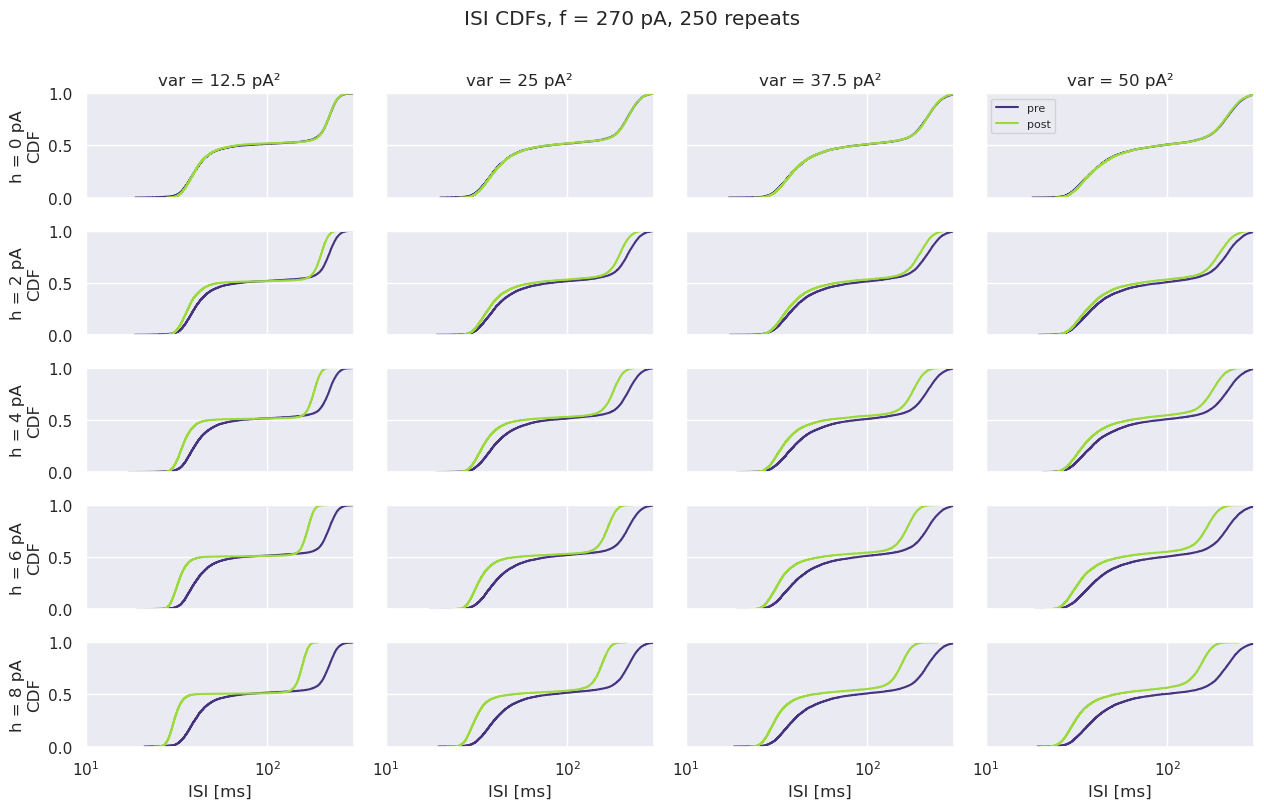

In [45]:
fig, ax = plt.subplots(len(H_EX), len(V_EX), figsize = (3.2*len(V_EX), 1.6*len(H_EX)), sharex = True, sharey = True)
for r, h in enumerate(H_EX):
    for c, v in enumerate(V_EX):
        a = ax[r, c]
        trials = [spikes(rep, v, h) for rep in range(N_REP)]
        pre, post = reference_isis([(np.diff(s[s >= T_DISCARD]), s[s >= T_DISCARD][1:]) for s in trials], true_cp)
        a.ecdf(pre, color = plt.cm.viridis(0.15), label = 'pre')
        a.ecdf(post, color = plt.cm.viridis(0.85), label = 'post')
        a.set_xscale('log')
        a.set_xlim(ISI_BINS[0], ISI_BINS[-1])
        if r == 0: a.set_title(f'var = {v:g} pA²')
        if c == 0: a.set_ylabel(f'h = {h} pA\nCDF')
for a in ax[-1]: a.set_xlabel('ISI [ms]')
ax[0, -1].legend(fontsize = 8)
fig.suptitle(f'ISI CDFs, f = {F} pA, {N_REP} repeats', y = 1.01)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_traces_f{F}_isi_cdfs.png', bbox_inches = 'tight')
plt.show()


## 1c. Single neuron rate change and regularity

From all saved repeats: pre (T_DISCARD to CP) and post (CP to T) firing rates, and the CV of the pooled pre/post ISIs,
as a function of noise variance.

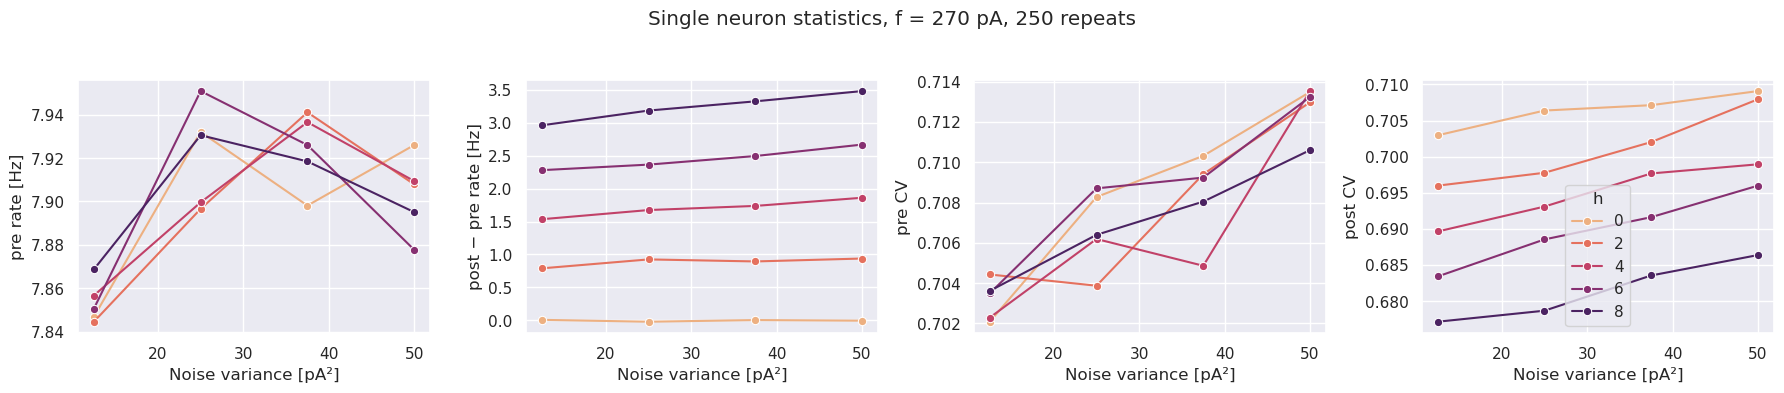

var,12.5,25.0,37.5,50.0
h,,,,
0,0.01,-0.02,0.00,-0.01
2,0.79,0.92,0.89,0.94
4,1.54,1.67,1.74,1.86
6,2.28,2.37,2.50,2.67
8,2.96,3.19,3.33,3.48


In [46]:
rows = []
for h in H_EX:
    for v in V_EX:
        trials = [spikes(rep, v, h) for rep in range(N_REP)]
        pre_rate = np.mean([np.sum((s >= T_DISCARD) & (s < true_cp)) for s in trials]) / (true_cp - T_DISCARD) * 1e3
        post_rate = np.mean([np.sum(s >= true_cp) for s in trials]) / (T - true_cp) * 1e3
        isis = [(np.diff(s[s >= T_DISCARD]), s[s >= T_DISCARD][1:]) for s in trials]
        pre, post = reference_isis(isis, true_cp)
        rows.append({'var': v, 'h': h, 'pre rate': pre_rate, 'post rate': post_rate, 'Δrate': post_rate - pre_rate,
                     'pre CV': pre.std() / pre.mean(), 'post CV': post.std() / post.mean()})
single = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 4, figsize = (18, 3.8))
for a, y in zip(ax, ['pre rate', 'Δrate', 'pre CV', 'post CV']):
    sns.lineplot(single, x = 'var', y = y, hue = 'h', palette = 'flare', marker = 'o', ax = a, legend = a is ax[-1])
    a.set_xlabel('Noise variance [pA²]')
ax[0].set_ylabel('pre rate [Hz]'); ax[1].set_ylabel('post − pre rate [Hz]')
fig.suptitle(f'Single neuron statistics, f = {F} pA, {N_REP} repeats', y = 1.03)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_traces_f{F}_single_stats.png', bbox_inches = 'tight')
plt.show()
single.pivot(index = 'h', columns = 'var', values = 'Δrate').round(2)

## 1d. Two-Gaussian mixture fit to the log-ISI distributions

A 2-component GMM is fitted to log10 of the post-CP ISIs pooled over all saved repeats (the pre-CP distribution does not
depend on h, so h = 0 is the baseline). Short component = smaller mean (burst ISIs, opaque lines), long component = larger mean
(regular ISIs, faded lines). Density ratio = mixture weight of the short component / weight of the long component.

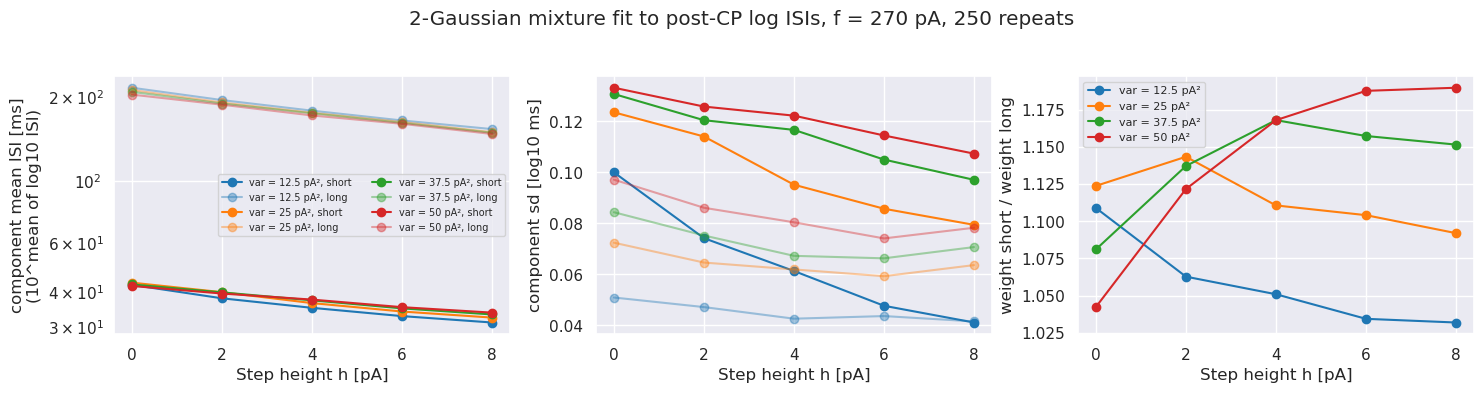

,var,h,mean short,mean long,sd short,sd long,density ratio
0,12.5,0,42.446,215.294,0.100,0.051,1.109
1,25.0,0,43.228,211.247,0.123,0.072,1.124
2,37.5,0,42.606,208.083,0.131,0.084,1.081
3,50.0,0,42.067,203.431,0.133,0.097,1.042
4,12.5,2,37.997,194.466,0.074,0.047,1.063
5,25.0,2,39.968,190.650,0.114,0.065,1.143
6,37.5,2,39.892,189.062,0.120,0.075,1.137
7,50.0,2,39.525,187.211,0.126,0.086,1.122
8,12.5,4,35.130,178.243,0.061,0.043,1.051
9,25.0,4,36.535,175.135,0.095,0.062,1.111


In [47]:
from sklearn.mixture import GaussianMixture


rows = []
for h in H_EX:
    for v in V_EX:
        trials = [spikes(rep, v, h) for rep in range(N_REP)]
        _, post = reference_isis([(np.diff(s[s >= T_DISCARD]), s[s >= T_DISCARD][1:]) for s in trials], true_cp)
        gmm = GaussianMixture(2, n_init = 5, random_state = 0).fit(np.log10(post)[:, None])
        s, l = np.argsort(gmm.means_.ravel())     # short, long component
        mu, sd, w = gmm.means_.ravel(), np.sqrt(gmm.covariances_.ravel()), gmm.weights_
        rows.append({'var': v, 'h': h, 'mean short': 10**mu[s], 'mean long': 10**mu[l],
                     'sd short': sd[s], 'sd long': sd[l], 'density ratio': w[s] / w[l]})
gmm_fits = pd.DataFrame(rows)

GMM_COLORS = dict(zip(V_EX, sns.color_palette('tab10', len(V_EX))))    # distinct hue per variance
ALPHA = {'short': 1.0, 'long': 0.4}
fig, ax = plt.subplots(1, 3, figsize = (15, 3.8))
for v in V_EX:
    d = gmm_fits[gmm_fits['var'] == v]
    for comp in ['short', 'long']:
        ax[0].plot(d['h'], d[f'mean {comp}'], 'o-', color = GMM_COLORS[v], alpha = ALPHA[comp], label = f'var = {v:g} pA², {comp}')
        ax[1].plot(d['h'], d[f'sd {comp}'], 'o-', color = GMM_COLORS[v], alpha = ALPHA[comp])
    ax[2].plot(d['h'], d['density ratio'], 'o-', color = GMM_COLORS[v], label = f'var = {v:g} pA²')
ax[0].set_yscale('log')
ax[0].set_ylabel('component mean ISI [ms]\n(10^mean of log10 ISI)')
ax[1].set_ylabel('component sd [log10 ms]')
ax[2].set_ylabel('weight short / weight long')
for a in ax: a.set_xlabel('Step height h [pA]')
ax[0].legend(fontsize = 7, ncol = 2)
ax[2].legend(fontsize = 8)
fig.suptitle(f'2-Gaussian mixture fit to post-CP log ISIs, f = {F} pA, {N_REP} repeats', y = 1.03)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_traces_f{F}_isi_gmm.png', bbox_inches = 'tight')
plt.savefig(f'./plots/{tag}_traces_f{F}_isi_gmm.png', bbox_inches = 'tight')
plt.show()
gmm_fits.round(3)

## 1d'. Mean and sd of the raw post-CP ISIs

Same pooled post-CP ISIs as 1d (h = 0 is the baseline), summarised directly by their mean and sd in ms, no mixture fit.

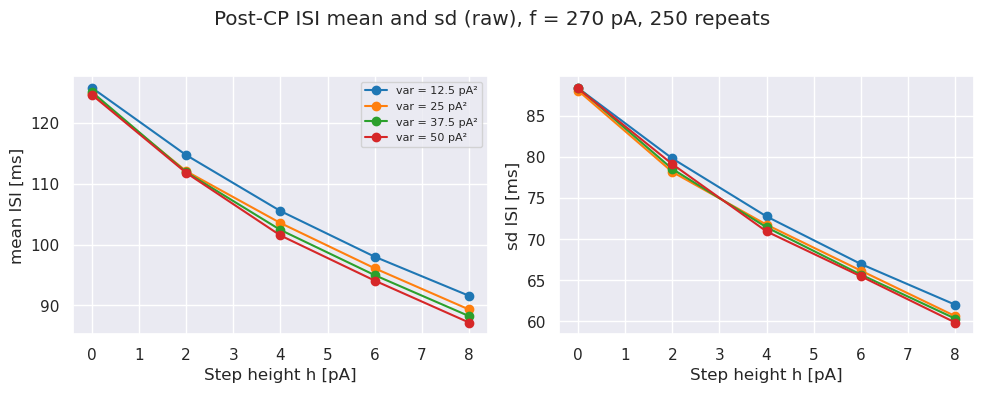

,var,h,mean,sd
0,12.5,0,125.77,88.41
1,25.0,0,124.73,88.11
2,37.5,0,125.08,88.45
3,50.0,0,124.61,88.36
4,12.5,2,114.70,79.83
5,25.0,2,112.06,78.19
6,37.5,2,111.89,78.55
7,50.0,2,111.79,79.14
8,12.5,4,105.51,72.76
9,25.0,4,103.53,71.76


In [48]:
rows = []
for h in H_EX:
    for v in V_EX:
        trials = [spikes(rep, v, h) for rep in range(N_REP)]
        _, post = reference_isis([(np.diff(s[s >= T_DISCARD]), s[s >= T_DISCARD][1:]) for s in trials], true_cp)
        rows.append({'var': v, 'h': h, 'mean': post.mean(), 'sd': post.std()})
raw_stats = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize = (10, 3.8))
for v in V_EX:
    d = raw_stats[raw_stats['var'] == v]
    ax[0].plot(d['h'], d['mean'], 'o-', color = GMM_COLORS[v], label = f'var = {v:g} pA²')
    ax[1].plot(d['h'], d['sd'], 'o-', color = GMM_COLORS[v])
ax[0].set_ylabel('mean ISI [ms]')
ax[1].set_ylabel('sd ISI [ms]')
for a in ax: a.set_xlabel('Step height h [pA]')
ax[0].legend(fontsize = 8)
fig.suptitle(f'Post-CP ISI mean and sd (raw), f = {F} pA, {N_REP} repeats', y = 1.03)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_traces_f{F}_isi_raw_stats.png', bbox_inches = 'tight')
plt.show()
raw_stats.round(2)


## 2a. Population PSTHs

The same k-trial resamples (same seeds) the PSTH change point analysis scored. Blue: mean ± sd over resamples;
black: one resample, i.e. a single input to a detector.

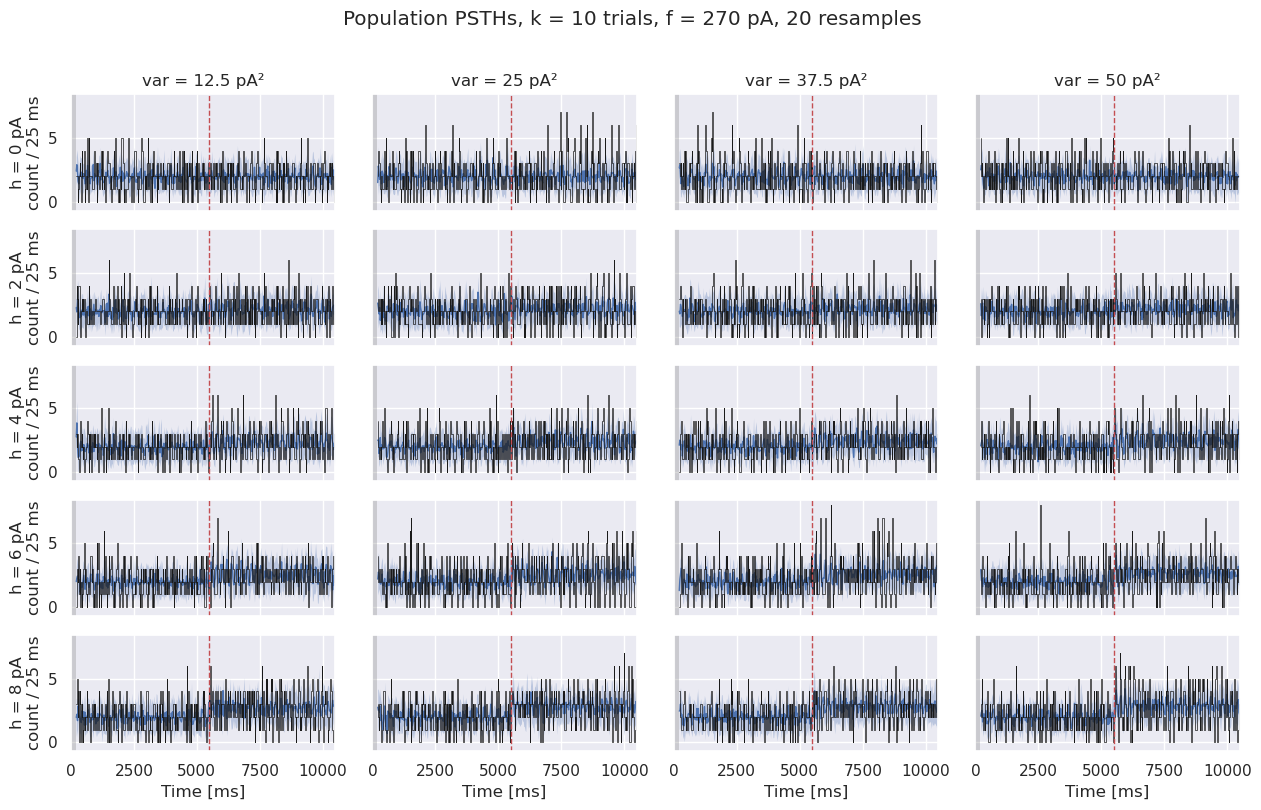

In [49]:
fig, ax = plt.subplots(len(H_EX), len(V_EX), figsize = (3.2*len(V_EX), 1.6*len(H_EX)), sharex = True, sharey = True)
for r, h in enumerate(H_EX):
    for c, v in enumerate(V_EX):
        a = ax[r, c]
        X, t_bin = condition_psths(v, h, F)
        tc = t_bin - PSTH_BIN/2
        mu, sd = X.mean(0), X.std(0)
        a.fill_between(tc, mu - sd, mu + sd, color = 'C0', alpha = 0.3, lw = 0)
        a.plot(tc, mu, color = 'C0', lw = 1)
        a.step(tc, X[0], where = 'mid', color = 'k', lw = 0.5)
        a.axvline(true_cp, color = 'r', ls = '--', lw = 1)
        a.axvspan(0, T_DISCARD, color = 'grey', alpha = 0.3, lw = 0)
        a.set_xlim(0, T)
        if r == 0: a.set_title(f'var = {v:g} pA²')
        if c == 0: a.set_ylabel(f'h = {h} pA\ncount / {PSTH_BIN} ms')
for a in ax[-1]: a.set_xlabel('Time [ms]')
fig.suptitle(f'Population PSTHs, k = {K} trials, f = {F} pA, {N_RES} resamples', y = 1.01)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_traces_f{F}_psth.png', bbox_inches = 'tight')
plt.show()

## 2a'. PSTH spike count distributions, pre vs post

Spike counts per PSTH bin from the 2a resamples, pooled before and after the CP (`reference_bins`):
the values a PSTH detector sees.

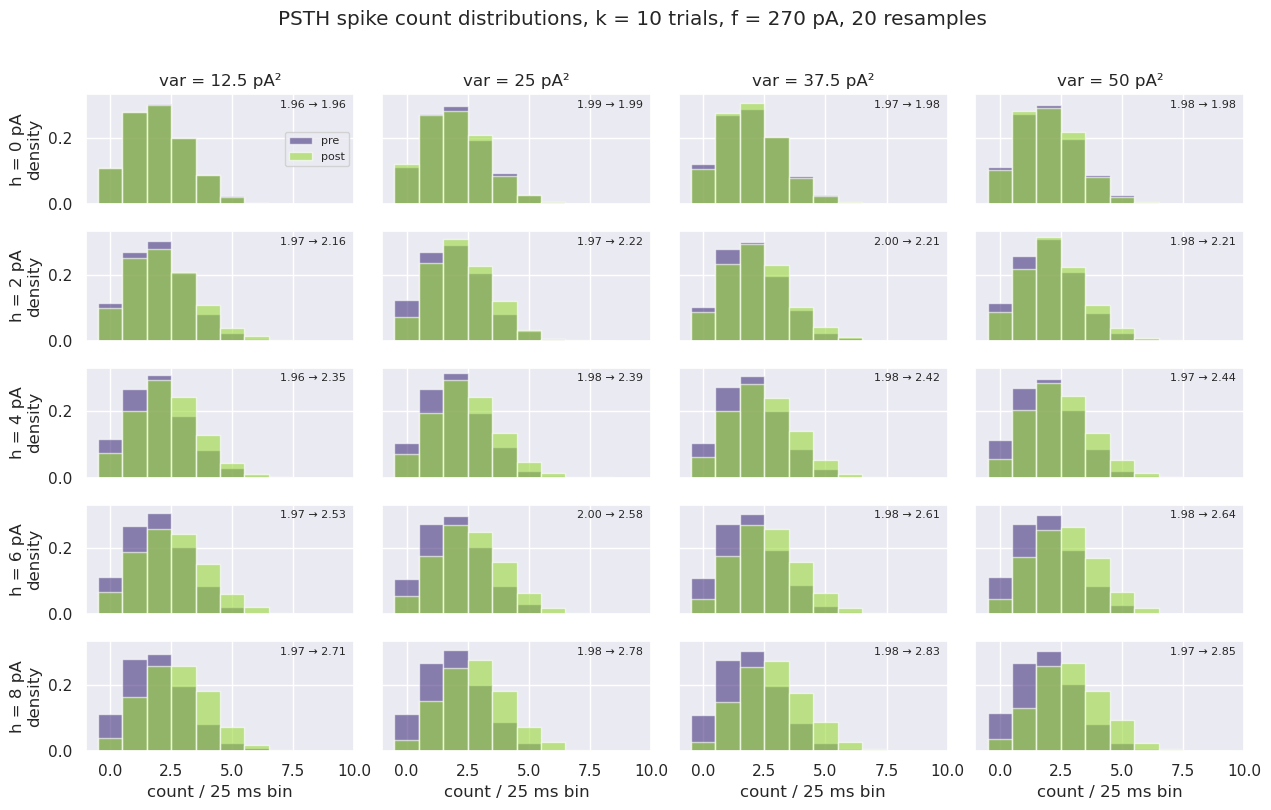

In [50]:
fig, ax = plt.subplots(len(H_EX), len(V_EX), figsize = (3.2*len(V_EX), 1.6*len(H_EX)), sharex = True, sharey = True)
for r, h in enumerate(H_EX):
    for c, v in enumerate(V_EX):
        a = ax[r, c]
        X, t_bin = condition_psths(v, h, F)
        pre, post = reference_bins(X, t_bin, PSTH_BIN, true_cp)
        bins = np.arange(min(pre.min(), post.min()) - 0.5, max(pre.max(), post.max()) + 1.5)
        a.hist(pre, bins = bins, density = True, alpha = 0.6, color = plt.cm.viridis(0.15), label = 'pre')
        a.hist(post, bins = bins, density = True, alpha = 0.6, color = plt.cm.viridis(0.85), label = 'post')
        a.text(0.97, 0.95, f'{pre.mean():.2f} → {post.mean():.2f}', transform = a.transAxes, ha = 'right', va = 'top', fontsize = 8)
        if r == 0: a.set_title(f'var = {v:g} pA²')
        if c == 0: a.set_ylabel(f'h = {h} pA\ndensity')
for a in ax[-1]: a.set_xlabel(f'count / {PSTH_BIN} ms bin')
ax[0, 0].legend(fontsize = 8, loc = 'center right')
fig.suptitle(f'PSTH spike count distributions, k = {K} trials, f = {F} pA, {N_RES} resamples', y = 1.01)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_traces_f{F}_psth_counts.png', bbox_inches = 'tight')
plt.show()

## 2b. PSTH pre/post separation

Per condition, the bin counts of all resamples pooled before and after the CP (`reference_bins`), summarised as
d′ = (post mean − pre mean) / pooled sd. This is the signal-to-noise a PSTH detector sees.

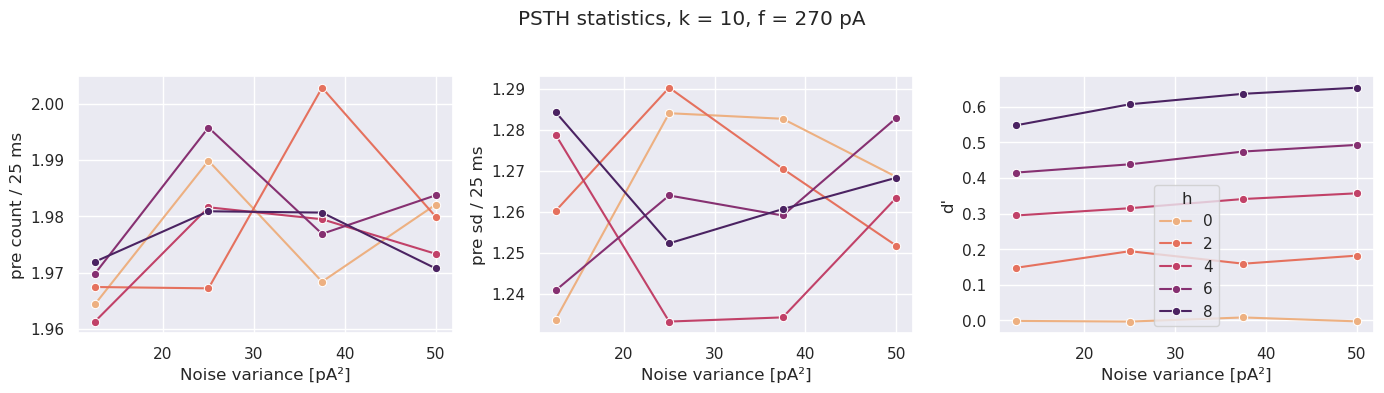

var,12.5,25.0,37.5,50.0
h,,,,
0,-0.00,-0.00,0.01,-0.00
2,0.15,0.19,0.16,0.18
4,0.29,0.31,0.34,0.36
6,0.42,0.44,0.47,0.49
8,0.55,0.61,0.64,0.65


In [51]:
rows = []
for h in H_EX:
    for v in V_EX:
        X, t_bin = condition_psths(v, h, F)
        pre, post = reference_bins(X, t_bin, PSTH_BIN, true_cp)
        rows.append({'var': v, 'h': h, 'pre mean': pre.mean(), 'pre sd': pre.std(),
                     "d'": (post.mean() - pre.mean()) / np.sqrt((pre.var() + post.var()) / 2)})
pop = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 3, figsize = (14, 3.8))
for a, y in zip(ax, ['pre mean', 'pre sd', "d'"]):
    sns.lineplot(pop, x = 'var', y = y, hue = 'h', palette = 'flare', marker = 'o', ax = a, legend = a is ax[-1])
    a.set_xlabel('Noise variance [pA²]')
ax[0].set_ylabel(f'pre count / {PSTH_BIN} ms'); ax[1].set_ylabel(f'pre sd / {PSTH_BIN} ms')
fig.suptitle(f'PSTH statistics, k = {K}, f = {F} pA', y = 1.03)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_traces_f{F}_psth_stats.png', bbox_inches = 'tight')
plt.show()
pop.pivot(index = 'h', columns = 'var', values = "d'").round(2)

## 3. Summary: dH = 4 pA, f = 260 pA, each noise variance

Injected current and membrane voltage are the section 1a run (current rebuilt from the same seed), not one of the saved trials.
Raster: all saved trials. ISIs: pooled over all saved trials (histograms), single 1a trial overlaid as rug ticks.

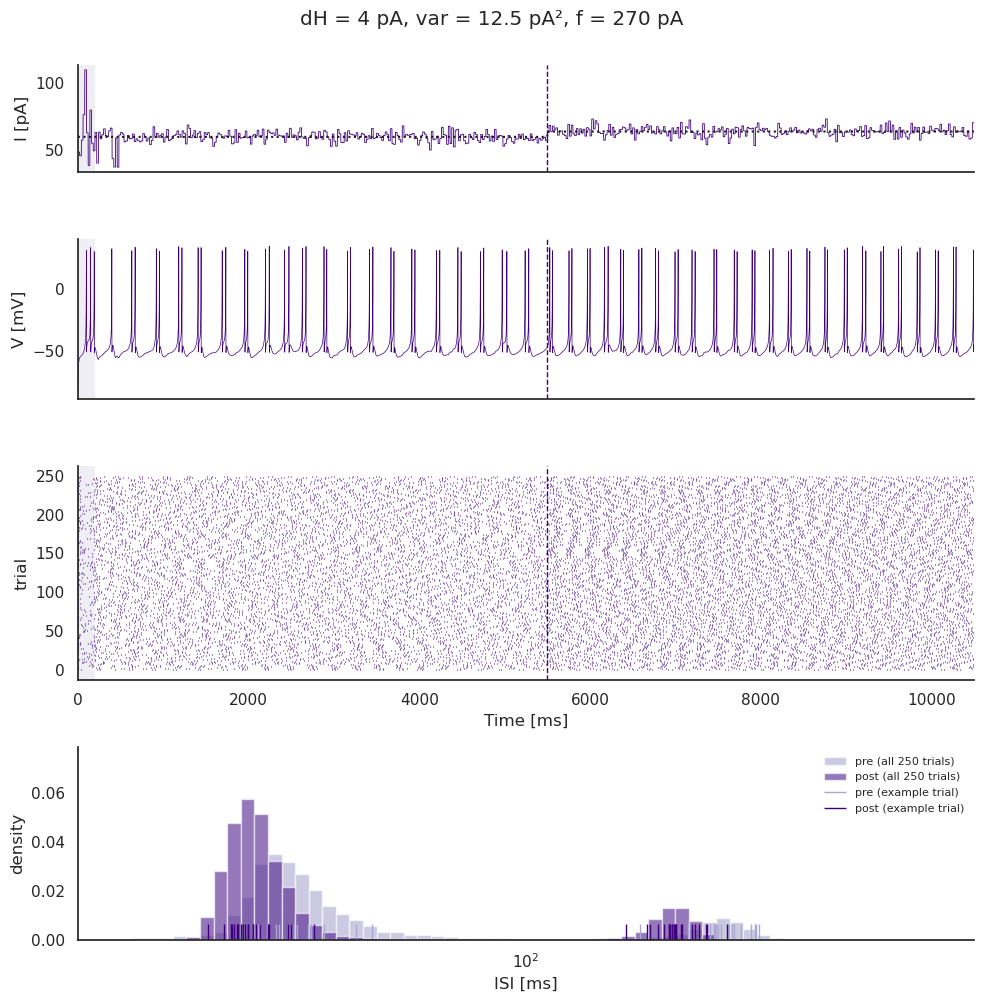

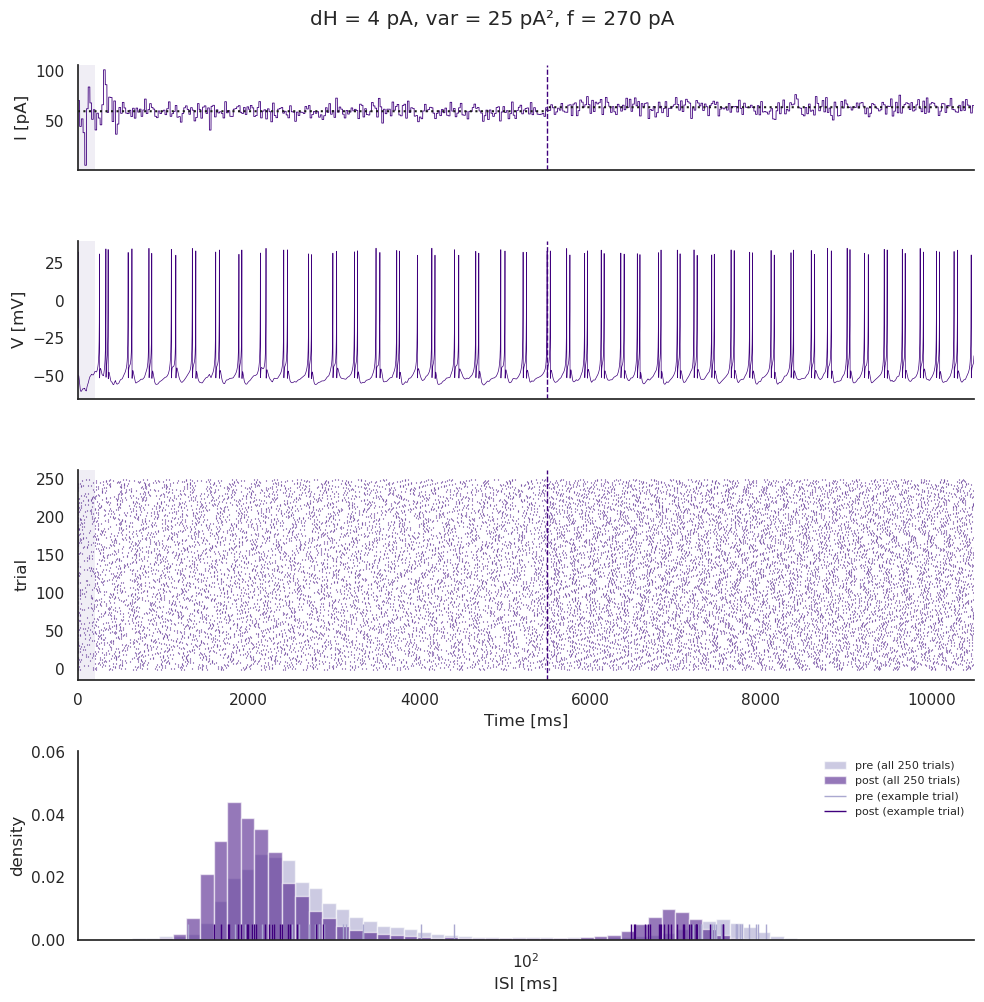

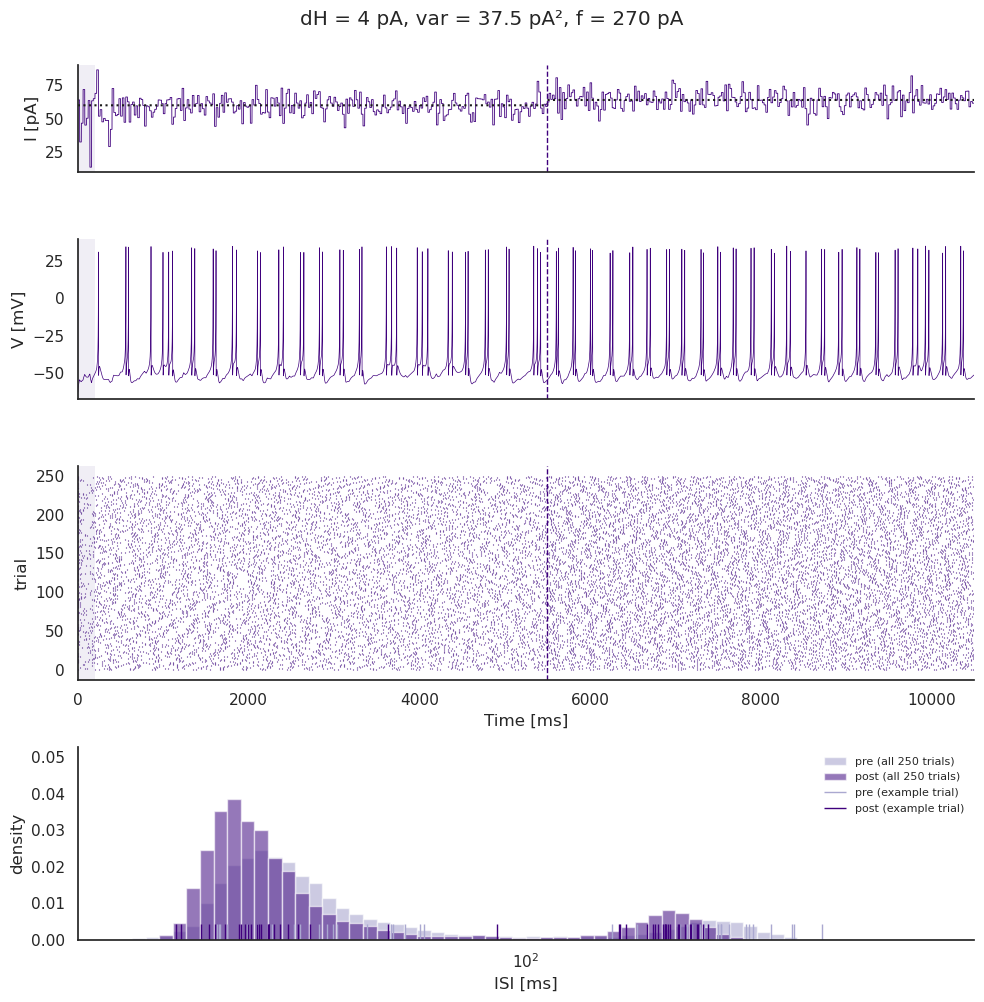

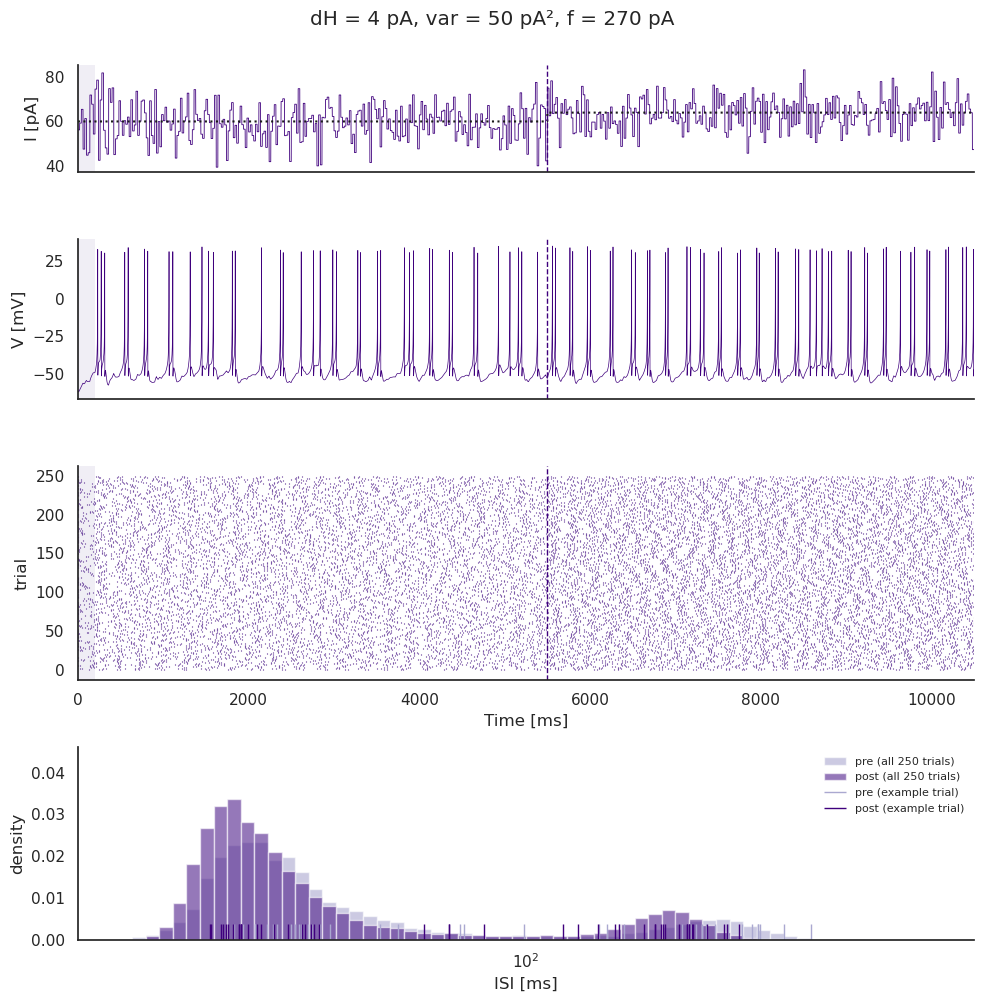

In [52]:
H_S = 4     # must be in H_EX (re-simulated in 1a); the original dH = 5 is not
PURPLE = sns.color_palette('Purples', as_cmap = True)
C_PRE, C_POST, C_DARK, C_SHADE = PURPLE(0.45), PURPLE(0.9), PURPLE(1.0), PURPLE(0.12)

# rebuild 1a's injected current: simulate_runs draws one noise vector per (var, h) (V_EX -> H_EX order)
# after np.random.seed(SEED), with sd = sqrt(var_warmup) during the warm-up
noise_steps = int(1/sim['noise_rate'] * (1000/sim['dt']))    # same formula as simulate_runs
np.random.seed(SEED)
draws = [np.random.normal(size = len(t) // noise_steps) for _ in V_EX for _ in H_EX]
warm = np.arange(len(t) // noise_steps) * noise_steps * sim['dt'] < WARM['t_warmup']
ISI_BINS_S = np.geomspace(20, 500, 61)    # ms, log axis: f = 260 pA has burst ISIs

for V in V_EX:
    sd = np.where(warm, np.sqrt(WARM['var_warmup']), np.sqrt(V))
    I = sim['I_0'] + H_S * (t >= true_cp) + np.repeat(draws[V_EX.index(V) * len(H_EX) + H_EX.index(H_S)] * sd, noise_steps)
    assert len(I) == len(t)

    v_ex = Vm[idx(V, H_S)]
    s_ex = np.asarray(Sp[idx(V, H_S)], dtype = float)
    s_ex = s_ex[~np.isnan(s_ex)]
    trials = [spikes(rep, V, H_S) for rep in range(N_REP)]
    pre, post = reference_isis([(np.diff(s[s >= T_DISCARD]), s[s >= T_DISCARD][1:]) for s in trials], true_cp)
    pre_ex, post_ex = reference_isis([(np.diff(s_ex[s_ex >= T_DISCARD]), s_ex[s_ex >= T_DISCARD][1:])], true_cp)

    with sns.axes_style('white'):
        fig, ax = plt.subplots(4, 1, figsize = (10, 10), height_ratios = [1, 1.5, 2, 1.8])
        for a in ax[1:3]: a.sharex(ax[0])
        ax[0].plot(t, I, color = C_DARK, lw = 0.6)
        ax[0].plot(t, sim['I_0'] + H_S * (t >= true_cp), color = 'k', ls = ':', lw = 1.5)    # mean current
        ax[0].set_ylabel('I [pA]')
        ax[1].plot(t, v_ex, color = C_DARK, lw = 0.5)
        ax[1].set_ylabel('V [mV]')
        ax[2].eventplot(trials, color = C_POST, lw = 0.8)
        ax[2].set_ylabel('trial')
        ax[2].set_xlabel('Time [ms]')
        for a in ax[:3]:
            a.axvspan(0, T_DISCARD, color = C_SHADE, lw = 0)
            a.axvline(true_cp, color = C_DARK, ls = '--', lw = 1)
            a.set_xlim(0, T)
        for a in ax[:2]: a.tick_params(labelbottom = False)

        a = ax[3]
        a.hist(pre, bins = ISI_BINS_S, density = True, alpha = 0.6, color = C_PRE, label = f'pre (all {N_REP} trials)')
        a.hist(post, bins = ISI_BINS_S, density = True, alpha = 0.6, color = C_POST, label = f'post (all {N_REP} trials)')
        sns.rugplot(x = pre_ex, ax = a, color = C_PRE, height = 0.08, lw = 1.5, label = 'pre (example trial)')
        sns.rugplot(x = post_ex, ax = a, color = C_DARK, height = 0.08, lw = 1.5, label = 'post (example trial)')
        a.set_xscale('log')
        a.set_xlabel('ISI [ms]')
        a.set_ylabel('density')
        a.legend(fontsize = 8, frameon = False)
        sns.despine(fig)
        fig.suptitle(f'dH = {H_S} pA, var = {V:g} pA², f = {F} pA', y = 1.0)
        fig.tight_layout()
        plt.savefig(f'./summary_plots/{tag}_example_var{V:g}_dH{H_S}_f{F}_current_voltage_raster_ISI.png', dpi = 300, bbox_inches = 'tight')
        plt.show()